In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings("ignore")

# 1) Data and Descriptive Statistics

In [2]:
data = pd.read_csv("dataset_2195_quake.csv")
data.head(10)

,focal_depth,latitude,longitude,richter
0,33,-52.26,28.30,6.7
1,36,45.53,150.93,5.8
2,57,41.85,142.78,5.8
3,67,29.19,141.15,6.2
4,30,-21.66,169.81,6.0
5,0,23.09,120.58,6.2
6,139,-20.70,169.92,6.1
7,60,22.33,93.58,6.0
8,50,-13.64,165.96,6.0
9,119,-16.31,-71.66,6.0


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2178 entries, 0 to 2177
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   focal_depth  2178 non-null   int64  
 1   latitude     2178 non-null   float64
 2   longitude    2178 non-null   float64
 3   richter      2178 non-null   float64
dtypes: float64(3), int64(1)
memory usage: 68.2 KB


In [4]:
data.describe()

,focal_depth,latitude,longitude,richter
count,2178.000000,2178.000000,2178.000000,2178.000000
mean,74.359963,7.961997,54.914835,5.977181
std,116.467797,30.545583,118.875581,0.189426
min,0.000000,-66.490000,-179.960000,5.800000
25%,21.000000,-12.432500,-67.782500,5.800000
50%,39.000000,0.210000,122.100000,5.900000
75%,68.000000,36.480000,146.860000,6.100000
max,656.000000,78.150000,180.000000,6.900000


# 2) Explorary Data Analysis

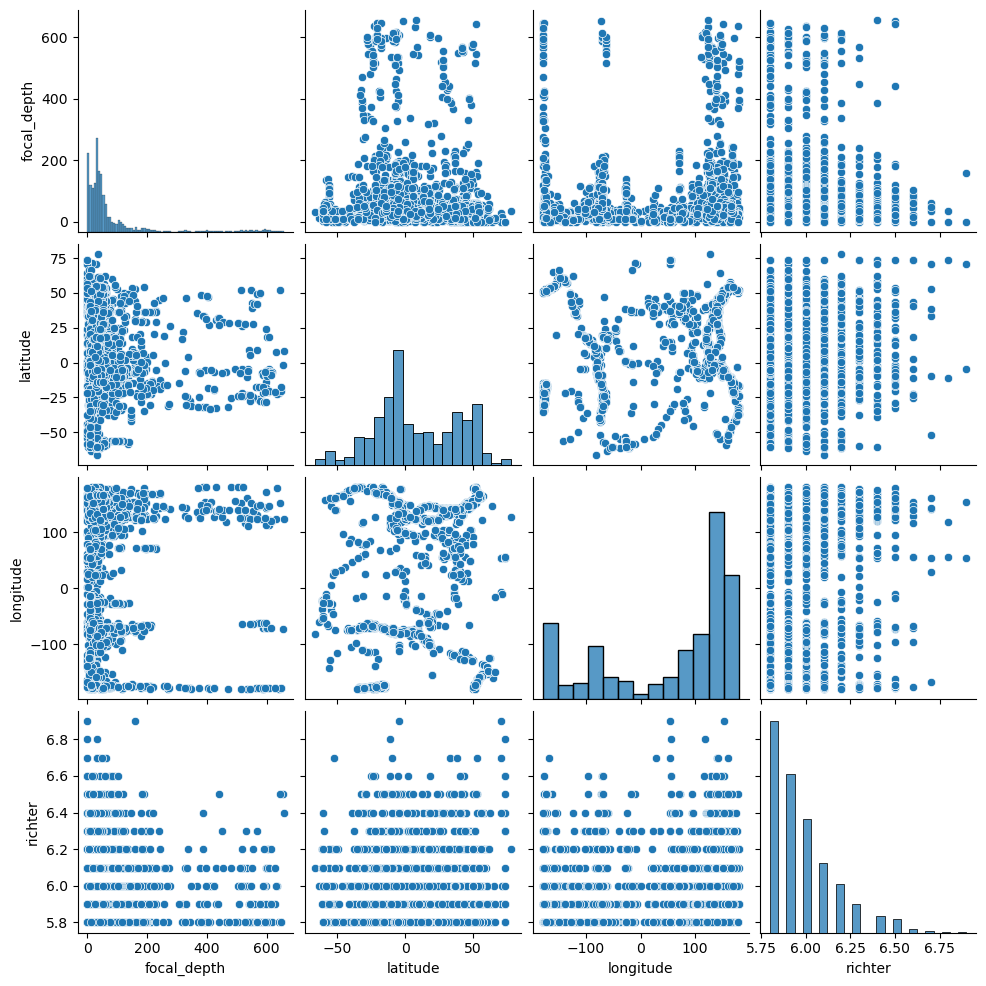

In [5]:
sns.pairplot(data=data)

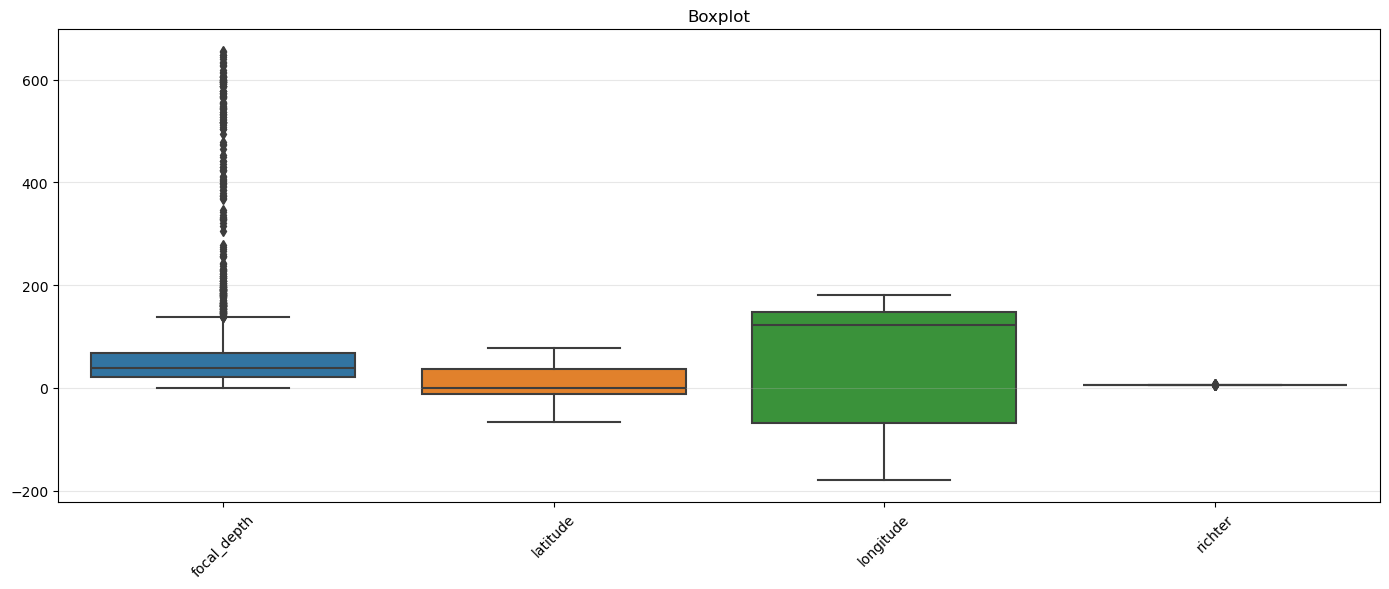

In [6]:
plt.figure(figsize=(14, 6))
sns.boxplot(data=data[data.columns])

plt.title("Boxplot")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

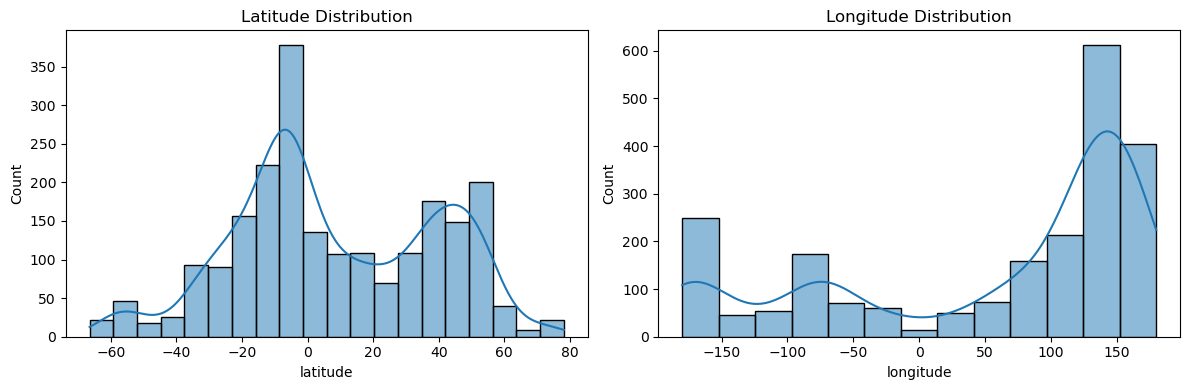

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data["latitude"], kde=True, ax=axes[0])
axes[0].set_title("Latitude Distribution")

sns.histplot(data["longitude"], kde=True, ax=axes[1])
axes[1].set_title("Longitude Distribution")

plt.tight_layout()
plt.show()

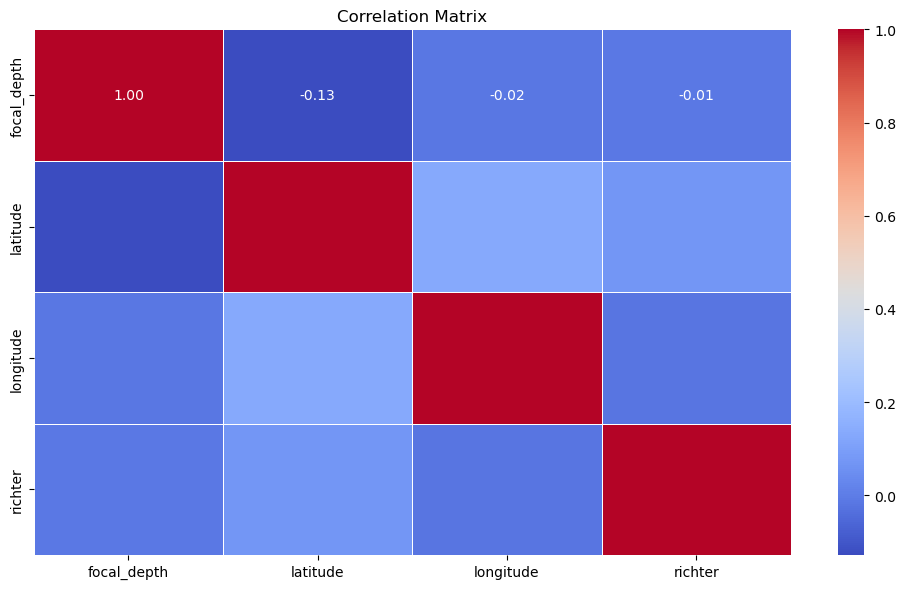

In [8]:
plt.figure(figsize=(10, 6))
corr = data.corr(numeric_only=True)

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

# 3) Clustering

In [9]:
scaler = StandardScaler()

data_scaled = scaler.fit_transform(data)

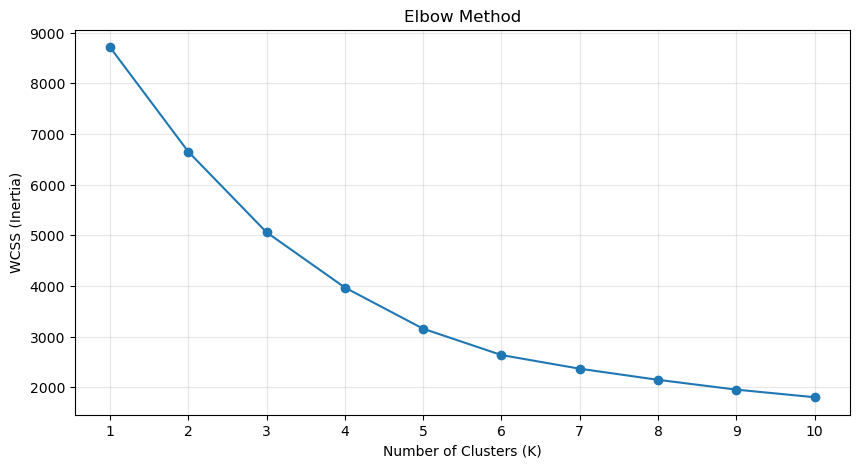

In [10]:
wcss = []

for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=1923,
        n_init=10
    )

    kmeans.fit(data_scaled)

    wcss.append(kmeans.inertia_)

plt.figure(figsize=(10, 5))
plt.plot(
    range(1, 11),
    wcss,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.title("Elbow Method")

plt.xticks(range(1, 11))
plt.grid(alpha=0.3)

plt.show()

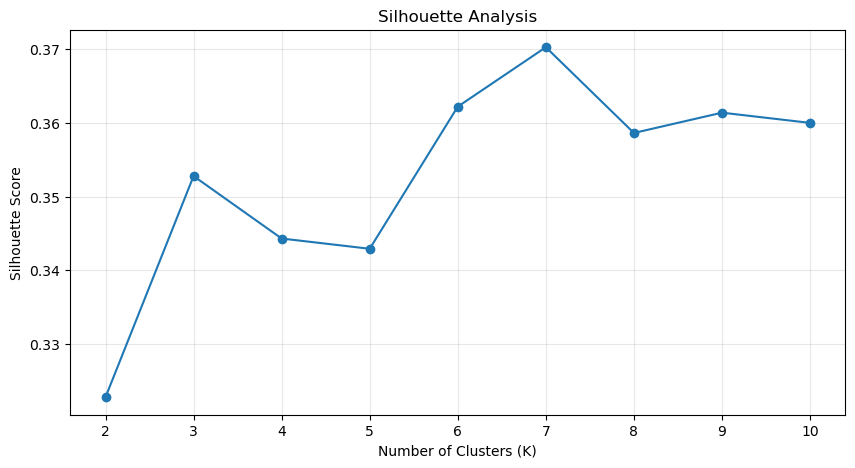

In [11]:
silhouette_scores = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=1923,
        n_init=10
    )

    labels = kmeans.fit_predict(data_scaled)

    score = silhouette_score(data_scaled, labels)

    silhouette_scores.append(score)


plt.figure(figsize=(10, 5))
plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis")

plt.grid(alpha=0.3)
plt.show()

In [12]:
kmeans = KMeans(
    n_clusters=3,
    random_state=1923,
    n_init=10
)

clusters = kmeans.fit_predict(data_scaled)

data["Cluster"] = clusters
data.head(10)

,focal_depth,latitude,longitude,richter,Cluster
0,33,-52.26,28.30,6.7,2
1,36,45.53,150.93,5.8,1
2,57,41.85,142.78,5.8,1
3,67,29.19,141.15,6.2,1
4,30,-21.66,169.81,6.0,1
5,0,23.09,120.58,6.2,1
6,139,-20.70,169.92,6.1,1
7,60,22.33,93.58,6.0,1
8,50,-13.64,165.96,6.0,1
9,119,-16.31,-71.66,6.0,2


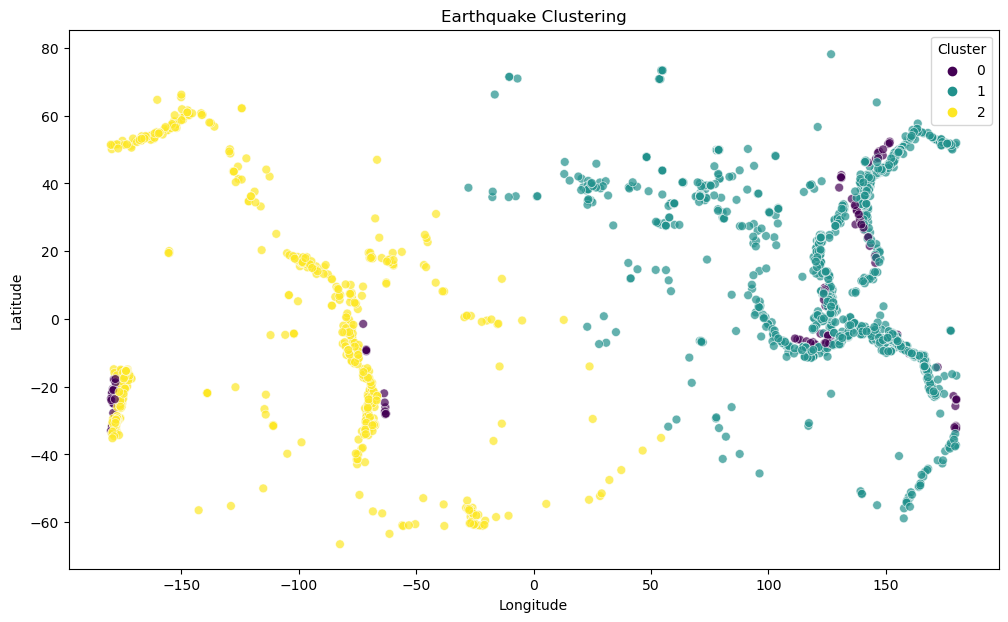

In [13]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=data,
    x="longitude",
    y="latitude",
    hue="Cluster",
    palette="viridis",
    s=40,
    alpha=0.7
)

plt.title("Earthquake Clustering")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="Cluster")

plt.show()

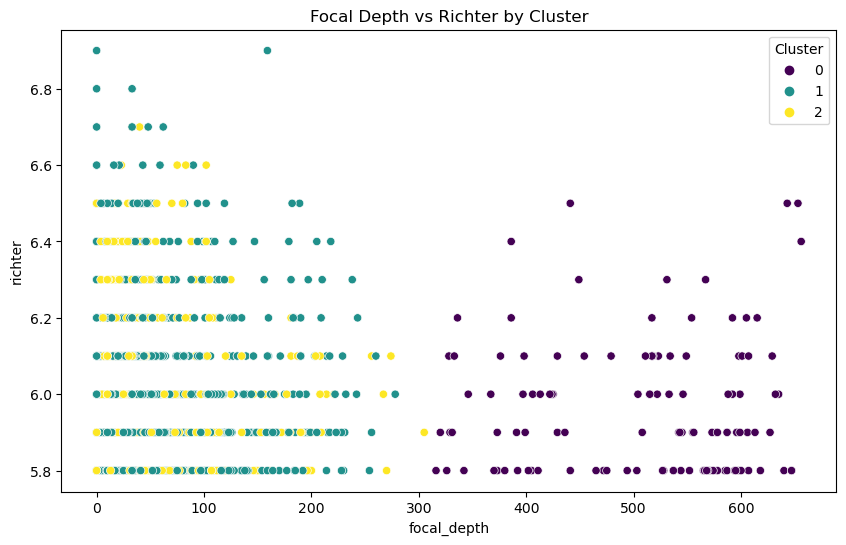

In [14]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=data,
    x="focal_depth",
    y="richter",
    hue="Cluster",
    palette="viridis"
)

plt.title("Focal Depth vs Richter by Cluster")
plt.show()

In [15]:
cluster_profile = data.groupby("Cluster")[data.columns].mean()
print(cluster_profile)

         focal_depth   latitude   longitude   richter  Cluster
Cluster                                                       
0         510.184874  -0.239328   38.280588  5.963025      0.0
1          49.764256  13.866147  127.412538  5.976217      1.0
2          47.798712  -4.138180 -109.774734  5.982126      2.0


In [16]:
data.groupby("Cluster")[data.columns].agg(
    ["mean", "median", "std", "min", "max"]
)

focal_depth                               latitude                    \
               mean median        std  min  max       mean median        std   
Cluster                                                                        
0        510.184874  534.0  95.990816  316  656  -0.239328  -7.08  26.032940   
1         49.764256   38.0  46.920127    0  278  13.866147   6.57  26.831474   
2         47.798712   33.0  46.978578    0  305  -4.138180 -15.35  35.187301   

                       ...   richter                            Cluster  \
           min    max  ...      mean median       std  min  max    mean   
Cluster                ...                                                
0       -33.02  52.36  ...  5.963025    5.9  0.173139  5.8  6.5     0.0   
1       -58.86  78.15  ...  5.976217    5.9  0.189947  5.8  6.9     1.0   
2       -66.49  66.22  ...  5.982126    5.9  0.191310  5.8  6.7     2.0   

                             
        median  std min max  
Cluster                      
0          0.0  0.0   0   0  
1          1.0  0.0   1   1  
2          2.0  0.0   2   2  

[3 rows x 25 columns]